# Homework 03

Dimensions de X: (100, 2)
Dimensions de y: (100,)


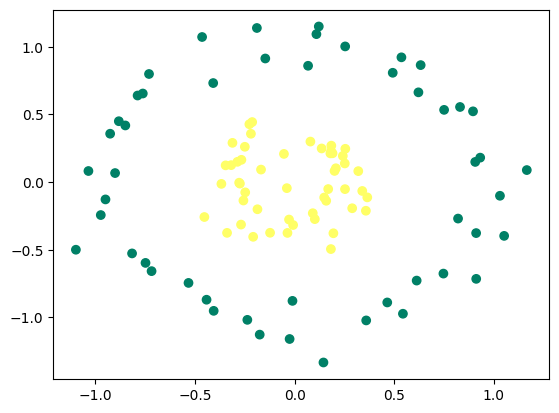

In [40]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles

# Génération des données
X, y = make_circles(n_samples=100, noise=0.1, factor=0.3, random_state=0)

# Affichage des dimensions
print('Dimensions de X:', X.shape)
print('Dimensions de y:', y.shape)

# Correction du scatter plot
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='summer')
plt.show()
#parametres = neural_network(X, y, n1= ?, n_iter= ?, learning_rate= ? )
# n1 = number of neurons

## 1 layer perceptron

In [46]:
def initialisation(n0, n1, n2):
    W1 = np.random.randn(n1, n0)
    b1 = np.zeros((n1, 1))
    W2 = np.random.randn(n2, n1)
    b2 = np.zeros((n2, 1))
    return {"W1": W1, "b1": b1, "W2": W2, "b2": b2}

def forward_propagation(X, parametres):
    W1, b1 = parametres['W1'], parametres['b1']
    W2, b2 = parametres['W2'], parametres['b2']

    Z1 = W1.dot(X) + b1
    A1 = 1 / (1 + np.exp(-Z1))
    Z2 = W2.dot(A1) + b2
    A2 = 1 / (1 + np.exp(-Z2))

    return {"A1": A1, "A2": A2}

def back_propagation(X, y, activations, parametres):
    A1, A2 = activations['A1'], activations['A2']
    W2 = parametres['W2']
    m = y.shape[1]

    dZ2 = A2 - y
    dW2 = 1 / m * dZ2.dot(A1.T)
    db2 = 1 / m * np.sum(dZ2, axis=1, keepdims=True)

    dZ1 = np.dot(W2.T, dZ2) * A1 * (1 - A1)
    dW1 = 1 / m * dZ1.dot(X.T)
    db1 = 1 / m * np.sum(dZ1, axis=1, keepdims=True)

    return {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2}

def update(gradients, parametres, learning_rate):
    for key in parametres.keys():
        parametres[key] -= learning_rate * gradients['d' + key]
    return parametres

In [72]:
from sklearn.metrics import accuracy_score

def train_network(X, y, n1=10, n_iter=1000, learning_rate=0.1, best_params=False):
    n0, n2 = X.shape[0], y.shape[0]
    parametres = initialisation(n0, n1, n2)
    train_loss, train_acc = [], []
    
    if best_params:
        print("Summary of training with best parameters:")
        print(f"Number of neurons (n1): {n1}")
        print(f"Learning rate: {learning_rate}")
        print(f"Number of iterations: {n_iter}")
        print("dimensions of X:", X.shape)
        print("dimensions of y:", y.shape)
        print("dimensions of W1:", parametres['W1'].shape)
        print("dimensions of b1:", parametres['b1'].shape)
        print("dimensions of W2:", parametres['W2'].shape)
        print("dimensions of b2:", parametres['b2'].shape)

    for i in range(n_iter):
        activations = forward_propagation(X, parametres)
        gradients = back_propagation(X, y, activations, parametres)
        parametres = update(gradients, parametres, learning_rate)

        if i % 10 == 0:
            # Loss (Log Loss)
            loss = -np.mean(y * np.log(activations['A2'] + 1e-8) + (1 - y) * np.log(1 - activations['A2'] + 1e-8))
            train_loss.append(loss)
            y_pred = (activations['A2'] >= 0.5).astype(int)
            train_acc.append(accuracy_score(y.flatten(), y_pred.flatten()))

    return parametres, train_loss, train_acc

In [73]:
def plot_decision_boundary(X, y, parametres):
    x_min, x_max = X[0, :].min() - 0.5, X[0, :].max() + 0.5
    y_min, y_max = X[1, :].min() - 0.5, X[1, :].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))
    
    grid = np.c_[xx.ravel(), yy.ravel()].T
    Z = forward_propagation(grid, parametres)['A2']
    Z = Z.reshape(xx.shape)
    
    plt.contourf(xx, yy, Z, cmap='summer', alpha=0.5)
    plt.scatter(X[0, :], X[1, :], c=y, cmap='summer', edgecolors='k')
    plt.title("Decision Boundary")
    plt.show()

In [74]:
def find_best_params(X_train, y_train, X_test, y_test, n1_options, lr_options, iterations):
    best_acc = 0
    best_params = {}
    results = []

    print(f"{'n1':<5} | {'LR':<5} | {'Iterations':<15} | {'Test Accuracy':<15}")
    print("-" * 50)

    for n1 in n1_options:
        for lr in lr_options:
            for iter in iterations:
                parametres, _, _ = train_network(X_train, y_train, n1=n1, n_iter=iter, learning_rate=lr)
                activations = forward_propagation(X_test, parametres)
                y_pred = (activations['A2'] >= 0.5).astype(int)
                acc = accuracy_score(y_test.flatten(), y_pred.flatten())
                results.append((n1, lr, iter, acc))
                print(f"{n1:<5} | {lr:<5} | {iter:<15} | {acc:<15.4f}")

                if acc > best_acc:
                    best_acc = acc
                    best_params = {'n1': n1, 'lr': lr, 'iterations': iter}

    print("-" * 50)
    print(f"Best Result: Accuracy {best_acc:.4f} with n1={best_params['n1']} and lr={best_params['lr']} and iterations={best_params['iterations']}")
    return best_params

In [75]:
from sklearn.model_selection import train_test_split

# Prepare data (Transpose for vectorization: features as rows)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_test = X_train.T, X_test.T
y_train, y_test = y_train.reshape((1, y_train.shape[0])), y_test.reshape((1, y_test.shape[0]))


# 1. Define the ranges you want to test
n1_candidates = [8, 16, 32]
lr_candidates = [0.1, 0.5, 1.0]
iterations = [100, 500, 1000]

# 2. Run the search
best_config = find_best_params(X_train, y_train, X_test, y_test, n1_candidates, lr_candidates, iterations)



n1    | LR    | Iterations      | Test Accuracy  
--------------------------------------------------
8     | 0.1   | 100             | 0.5500         
8     | 0.1   | 500             | 0.6500         
8     | 0.1   | 1000            | 0.8250         
8     | 0.5   | 100             | 0.6750         
8     | 0.5   | 500             | 1.0000         
8     | 0.5   | 1000            | 1.0000         
8     | 1.0   | 100             | 0.7750         
8     | 1.0   | 500             | 1.0000         
8     | 1.0   | 1000            | 1.0000         
16    | 0.1   | 100             | 0.5500         
16    | 0.1   | 500             | 0.6750         
16    | 0.1   | 1000            | 0.8750         
16    | 0.5   | 100             | 0.7000         
16    | 0.5   | 500             | 1.0000         
16    | 0.5   | 1000            | 1.0000         
16    | 1.0   | 100             | 0.6750         
16    | 1.0   | 500             | 1.0000         
16    | 1.0   | 1000            | 1.0000         

In [76]:
# 3. Train the final model using the best parameters found
final_params, final_losses, final_accs = train_network(
    X_train, 
    y_train, 
    n1=best_config['n1'], 
    n_iter=3000, # More iterations for the final model
    learning_rate=best_config['lr'],
    best_params=True
)



Summary of training with best parameters:
Number of neurons (n1): 8
Learning rate: 0.5
Number of iterations: 3000
dimensions of X: (2, 160)
dimensions of y: (1, 160)
dimensions of W1: (8, 2)
dimensions of b1: (8, 1)
dimensions of W2: (1, 8)
dimensions of b2: (1, 1)


<b>Summry</b>

as we can see, the best parameters are n1=16, lr=0.5 and iterations=1000 with an accuracy of 1.0000 on the test set. We will now train a final model using these parameters and plot the decision boundary.

- the dimensions of X: (2, 80)
- the dimensions of y: (1, 80)
- the dimensions of W1: (16, 2)
- the dimensions of b1: (16, 1)
- the dimensions of W2: (1, 16)
- the dimensions of b2: (1, 1)

we should use x transposed for the neural network to work correctly, as the dimensions of W1 and W2 are designed for that.

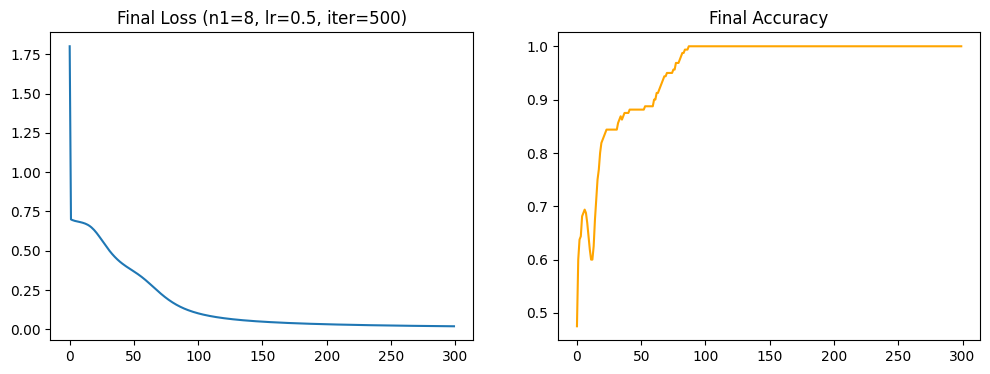

In [78]:
# 4. Final Visualization
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(final_losses)
plt.title(f"Final Loss (n1={best_config['n1']}, lr={best_config['lr']}, iter={best_config['iterations']})")
plt.subplot(1, 2, 2)
plt.plot(final_accs, color='orange')
plt.title("Final Accuracy")
plt.show()



those are the accuracy and loss curves for the final model trained with the best parameters found during the search. The left plot shows how the loss decreases over iterations, while the right plot shows how the accuracy improves.

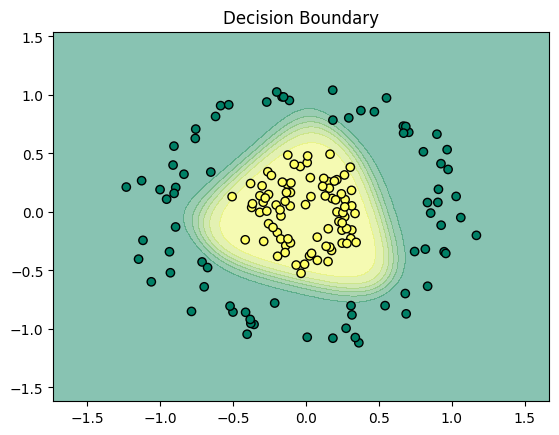

In [79]:
plot_decision_boundary(X_train, y_train, final_params)

how we can see the decision boundary is not perfect, we can try to increase the number of neurons in the hidden layer, or increase the number of iterations, or try different learning rates.

## 2) Extension to a Multilayer Perceptron (MLP)

Below is a simple and clear extension of the previous code to handle **multiple hidden layers**.

- Hidden layers: ReLU activation
- Output layer: Sigmoid activation (binary classification)
- Loss: Binary cross-entropy

In [ ]:
# ---------- MLP: helper functions ----------

def init_mlp(layer_dims, seed=42):
    np.random.seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        # He-like scaling for stable training with ReLU
        params[f"W{l}"] = np.random.randn(layer_dims[l], layer_dims[l - 1]) * np.sqrt(2 / layer_dims[l - 1])
        params[f"b{l}"] = np.zeros((layer_dims[l], 1))
    return params


def relu(Z):
    return np.maximum(0, Z)


def sigmoid(Z):
    return 1 / (1 + np.exp(-Z))


def forward_mlp(X, params):
    caches = {"A0": X}
    L = len(params) // 2

    for l in range(1, L):
        Z = params[f"W{l}"].dot(caches[f"A{l-1}"]) + params[f"b{l}"]
        A = relu(Z)
        caches[f"Z{l}"] = Z
        caches[f"A{l}"] = A

    # Output layer
    ZL = params[f"W{L}"].dot(caches[f"A{L-1}"]) + params[f"b{L}"]
    AL = sigmoid(ZL)
    caches[f"Z{L}"] = ZL
    caches[f"A{L}"] = AL
    return AL, caches


def compute_loss(y, y_hat):
    eps = 1e-8
    return -np.mean(y * np.log(y_hat + eps) + (1 - y) * np.log(1 - y_hat + eps))


def backward_mlp(y, params, caches):
    grads = {}
    m = y.shape[1]
    L = len(params) // 2

    # Output layer gradient (sigmoid + BCE)
    dZ = caches[f"A{L}"] - y

    for l in reversed(range(1, L + 1)):
        A_prev = caches[f"A{l-1}"]
        grads[f"dW{l}"] = (1 / m) * dZ.dot(A_prev.T)
        grads[f"db{l}"] = (1 / m) * np.sum(dZ, axis=1, keepdims=True)

        if l > 1:
            dA_prev = params[f"W{l}"].T.dot(dZ)
            Z_prev = caches[f"Z{l-1}"]
            dZ = dA_prev * (Z_prev > 0)  # ReLU derivative

    return grads


def update_mlp(params, grads, lr):
    L = len(params) // 2
    for l in range(1, L + 1):
        params[f"W{l}"] -= lr * grads[f"dW{l}"]
        params[f"b{l}"] -= lr * grads[f"db{l}"]
    return params


def predict_mlp(X, params):
    y_hat, _ = forward_mlp(X, params)
    return (y_hat >= 0.5).astype(int)


def train_mlp(X, y, layer_dims, n_iter=3000, lr=0.05, seed=42, verbose=False):
    params = init_mlp(layer_dims, seed=seed)
    losses, accs = [], []

    for i in range(n_iter):
        y_hat, caches = forward_mlp(X, params)
        loss = compute_loss(y, y_hat)
        grads = backward_mlp(y, params, caches)
        params = update_mlp(params, grads, lr)

        if i % 100 == 0:
            losses.append(loss)
            y_pred = (y_hat >= 0.5).astype(int)
            acc = accuracy_score(y.flatten(), y_pred.flatten())
            accs.append(acc)
            if verbose:
                print(f"Iter {i:4d} | Loss: {loss:.4f} | Acc: {acc:.4f}")

    return params, losses, accs